In [1]:

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    ConfusionMatrixDisplay
)

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Mengatur penggunaan memori GPU
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("GPU tersedia:", gpus)

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)


I0000 00:00:1791571957.715558   42714 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow: 2.21.0
GPU tersedia: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:

TRAIN_DIR = "../dataset/Train_Set"

classes = ["Aman", "Lainnya", "Rusak"]

image_paths = []
labels = []

IMG_EXTS = {
    ".jpg", ".jpeg", ".png",
    ".bmp", ".webp", ".tif", ".tiff", ".jfif"
}

for class_name in classes:
    class_dir = os.path.join(TRAIN_DIR, class_name)

    if not os.path.isdir(class_dir):
        raise FileNotFoundError(
            f"Folder kelas tidak ditemukan: {class_dir}"
        )

    for filename in os.listdir(class_dir):
        image_path = os.path.join(class_dir, filename)

        if (
            os.path.isfile(image_path)
            and os.path.splitext(filename)[1].lower() in IMG_EXTS
        ):
            image_paths.append(image_path)
            labels.append(class_name)

df = pd.DataFrame({
    "filepath": image_paths,
    "label": labels
})

label_map = {
    "Aman": 0,
    "Lainnya": 1,
    "Rusak": 2
}

df["label_id"] = df["label"].map(label_map)

print("Total gambar:", len(df))
print("\nDistribusi kelas:")
print(df["label"].value_counts())


Total gambar: 12224

Distribusi kelas:
label
Aman       8800
Rusak      3001
Lainnya     423
Name: count, dtype: int64


In [3]:
bad_tf_files = []

for i, path in enumerate(df["filepath"], start=1):
    try:
        image = tf.io.read_file(path)
        image = tf.io.decode_image(
            image,
            channels=3,
            expand_animations=False
        )
        _ = image.numpy()
    except Exception as e:
        bad_tf_files.append((path, str(e)[:150]))

    if i % 1000 == 0:
        print(f"Diperiksa: {i}/{len(df)}")

print("\nTotal gambar gagal dibaca TensorFlow:", len(bad_tf_files))

for path, error in bad_tf_files[:10]:
    print(path)
    print("Error:", error)

I0000 00:00:1791571999.069280   42714 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


Diperiksa: 1000/12224
Diperiksa: 2000/12224
Diperiksa: 3000/12224
Diperiksa: 4000/12224
Diperiksa: 5000/12224
Diperiksa: 6000/12224


W0000 00:00:1791572064.736452   42714 local_rendezvous.cc:412] Local rendezvous is aborting with status: INVALID_ARGUMENT: Unknown image file format. One of JPEG, JPEG XL, PNG, GIF, BMP, WebP required.


Diperiksa: 7000/12224
Diperiksa: 8000/12224
Diperiksa: 9000/12224
Diperiksa: 10000/12224
Diperiksa: 11000/12224
Diperiksa: 12000/12224

Total gambar gagal dibaca TensorFlow: 1
../dataset/Train_Set/Aman/Aman_06692.jpg
Error: {{function_node __wrapped__DecodeImage_device_/job:localhost/replica:0/task:0/device:CPU:0}} Unknown image file format. One of JPEG, JPEG XL, PNG, GIF


In [4]:
bad_tf_paths = [
    "../dataset/Train_Set/Aman/Aman_06692.jpg"
]

df = df[~df["filepath"].isin(bad_tf_paths)].copy()
df = df.reset_index(drop=True)

print("Total gambar setelah dibersihkan:", len(df))
print(df["label"].value_counts())

Total gambar setelah dibersihkan: 12223
label
Aman       8799
Rusak      3001
Lainnya     423
Name: count, dtype: int64


In [5]:

from sklearn.model_selection import train_test_split

SEED = 42

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=SEED,
    stratify=df["label_id"]
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

print("Data training:", len(train_df))
print("Data validation:", len(val_df))

print("\nDistribusi training:")
print(train_df["label"].value_counts())

print("\nDistribusi validation:")
print(val_df["label"].value_counts())


Data training: 9778
Data validation: 2445

Distribusi training:
label
Aman       7039
Rusak      2401
Lainnya     338
Name: count, dtype: int64

Distribusi validation:
label
Aman       1760
Rusak       600
Lainnya      85
Name: count, dtype: int64


In [6]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 8

def load_image(filepath, label):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label


def create_dataset(dataframe, training=False):
    paths = dataframe["filepath"].values
    labels_array = dataframe["label_id"].values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels_array)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=min(len(dataframe), 1000),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=2
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(1)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)

for images, labels_batch in train_ds.take(1):
    print("Shape gambar:", images.shape)
    print("Shape label:", labels_batch.shape)


Shape gambar: (8, 224, 224, 3)
Shape label: (8,)


In [7]:

from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1, 2]),
    y=train_df["label_id"].values
)

class_weight_dict = {
    i: float(weight)
    for i, weight in enumerate(class_weights)
}

print("Label map:", label_map)
print("Class weights:", class_weight_dict)


Label map: {'Aman': 0, 'Lainnya': 1, 'Rusak': 2}
Class weights: {0: 0.4630392574702846, 1: 9.642998027613412, 2: 1.35748993474941}


In [8]:

base_model = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))

# Augmentasi hanya aktif saat training.
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.05)(x)
x = layers.RandomZoom(0.1)(x)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(
    3,
    activation="softmax"
)(x)

model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,053,414 (15.46 MB)

 Trainable params: 3,843 (15.01 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [9]:

os.makedirs("../models", exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "../models/efficientnetb0_best.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]


In [10]:

EPOCHS_HEAD = 10

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_HEAD,
    class_weight=class_weight_dict,
    callbacks=callbacks
)


Epoch 1/10


/home/brt/datascape-gpu/.venv312/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1791572116.780750   43139 cuda_dnn.cc:461] Loaded cuDNN version 92700


1223/1223 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.6441 - loss: 0.7111
Epoch 1: val_loss improved from None to 0.60213, saving model to ../models/efficientnetb0_best.keras

Epoch 1: finished saving model to ../models/efficientnetb0_best.keras
1223/1223 ━━━━━━━━━━━━━━━━━━━━ 96s 69ms/step - accuracy: 0.6441 - loss: 0.7111 - val_accuracy: 0.7382 - val_loss: 0.6021 - learning_rate: 0.0010
Epoch 2/10
1222/1223 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7044 - loss: 0.5810
Epoch 2: val_loss did not improve from 0.60213
1223/1223 ━━━━━━━━━━━━━━━━━━━━ 81s 67ms/step - accuracy: 0.7043 - loss: 0.5810 - val_accuracy: 0.6601 - val_loss: 0.7121 - learning_rate: 0.0010
Epoch 3/10
1222/1223 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7174 - loss: 0.5465
Epoch 3: val_loss did not improve from 0.60213

Epoch 3: ReduceLROnPlateau reducing learning rate to 0.00020000000949949026.
1223/1223 ━━━━━━━━━━━━━━━━━━━━ 81s 66ms/step - accuracy: 0.7174 - loss: 0.5465 - val_accuracy: 0.7096 - val_lo

In [11]:

base_model.trainable = True

# Bekukan sebagian besar layer dan latih 30 layer terakhir.
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Batch Normalization tetap dibekukan agar training lebih stabil.
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

EPOCHS_FINE = 10

history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE,
    class_weight=class_weight_dict,
    callbacks=callbacks
)


Epoch 1/10


E0000 00:00:1791572952.980959   42714 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/efficientnetb0_1/block2b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


1223/1223 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.7466 - loss: 0.4715
Epoch 1: val_loss improved from 0.58184 to 0.57287, saving model to ../models/efficientnetb0_best.keras

Epoch 1: finished saving model to ../models/efficientnetb0_best.keras
1223/1223 ━━━━━━━━━━━━━━━━━━━━ 114s 84ms/step - accuracy: 0.7466 - loss: 0.4715 - val_accuracy: 0.7530 - val_loss: 0.5729 - learning_rate: 1.0000e-05
Epoch 2/10
1222/1223 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step - accuracy: 0.7618 - loss: 0.4513
Epoch 2: val_loss improved from 0.57287 to 0.57156, saving model to ../models/efficientnetb0_best.keras

Epoch 2: finished saving model to ../models/efficientnetb0_best.keras
1223/1223 ━━━━━━━━━━━━━━━━━━━━ 98s 80ms/step - accuracy: 0.7618 - loss: 0.4513 - val_accuracy: 0.7505 - val_loss: 0.5716 - learning_rate: 1.0000e-05
Epoch 3/10
1222/1223 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.7713 - loss: 0.4341
Epoch 3: val_loss improved from 0.57156 to 0.56578, saving model to ../models/efficientnetb0_be

306/306 ━━━━━━━━━━━━━━━━━━━━ 16s 45ms/step
Macro F1: 0.7407137438322963

Classification Report:
              precision    recall  f1-score   support

        Aman       0.92      0.76      0.83      1760
     Lainnya       0.64      0.86      0.73        85
       Rusak       0.55      0.81      0.66       600

    accuracy                           0.77      2445
   macro avg       0.70      0.81      0.74      2445
weighted avg       0.82      0.77      0.78      2445



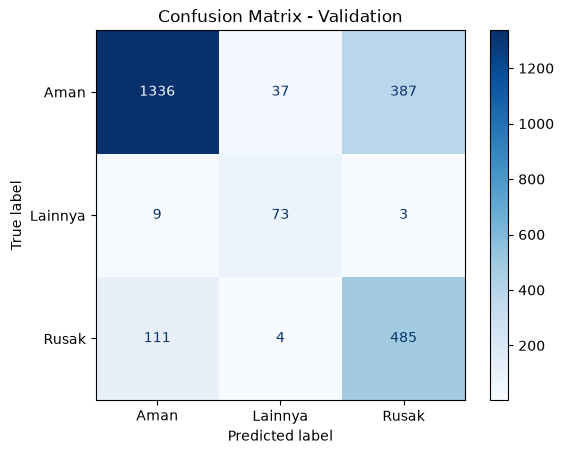

In [12]:

best_model = tf.keras.models.load_model(
    "../models/efficientnetb0_best.keras"
)

y_true = np.concatenate([
    labels_batch.numpy()
    for _, labels_batch in val_ds
])

y_prob = best_model.predict(val_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print(
    "Macro F1:",
    f1_score(y_true, y_pred, average="macro")
)

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=classes,
        zero_division=0
    )
)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

display.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Validation")
plt.show()


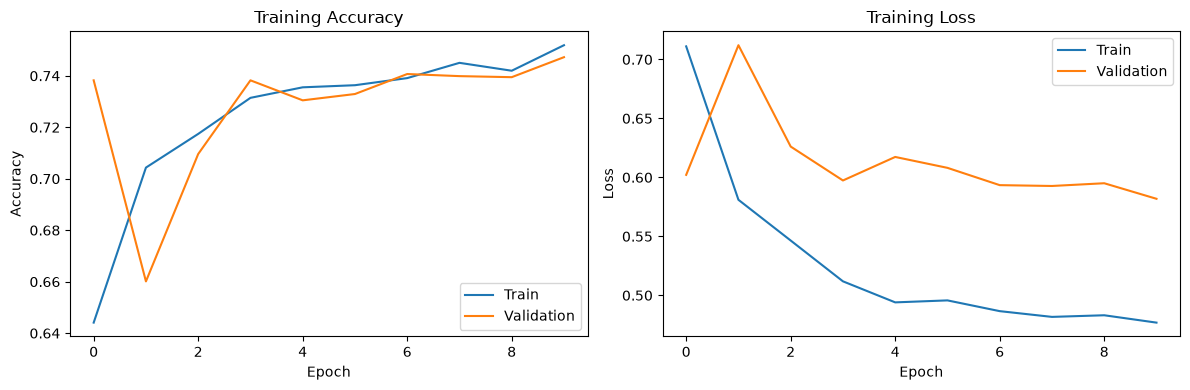

In [13]:

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history_head.history["accuracy"], label="Train")
plt.plot(history_head.history["val_accuracy"], label="Validation")
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_head.history["loss"], label="Train")
plt.plot(history_head.history["val_loss"], label="Validation")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


In [14]:

best_model.save("../models/efficientnetb0_final.keras")

print("Model final berhasil disimpan.")


Model final berhasil disimpan.


In [17]:

# %%
import os
import pandas as pd
import numpy as np
import tensorflow as tf


# Folder gambar test
TEST_DIR = "../dataset/Test_Set"

# Memuat model dengan validation loss terbaik
best_model = tf.keras.models.load_model(
    "../models/efficientnetb0_best.keras"
)

IMG_SIZE = (224, 224)
BATCH_SIZE = 8

# Mengambil nama file gambar dari folder test
valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

test_files = sorted([
    filename
    for filename in os.listdir(TEST_DIR)
    if os.path.isfile(os.path.join(TEST_DIR, filename))
    and os.path.splitext(filename)[1].lower() in valid_exts
])

print("Total gambar test:", len(test_files))

# Fungsi membaca dan memproses gambar

def load_test_image(filepath):
    image = tf.io.read_file(filepath)

    image = tf.io.decode_image(
        image,
        channels=0,
        expand_animations=False
    )

    image = tf.cond(
        tf.equal(tf.shape(image)[-1], 1),
        lambda: tf.image.grayscale_to_rgb(image),
        lambda: image[:, :, :3]
    )

    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image


# Membuat dataset test
test_paths = [
    os.path.join(TEST_DIR, filename)
    for filename in test_files
]

test_ds = tf.data.Dataset.from_tensor_slices(test_paths)
test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=2
)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(1)

# Prediksi kelas
probabilities = best_model.predict(test_ds, verbose=1)
predicted_ids = np.argmax(probabilities, axis=1)

# Mengubah angka menjadi nama kelas
classes = ["Aman", "Lainnya", "Rusak"]
predicted_labels = [classes[i] for i in predicted_ids]

# Membuat submission
submission = pd.DataFrame({
    "filename": test_files,
    "label": predicted_labels
})

# Menyimpan file
submission.to_csv("../submission.csv", index=False)

print("\nDistribusi prediksi:")
print(submission["label"].value_counts())

print("\nContoh submission:")
print(submission.head(10))

print("\nFile tersimpan di ../submission.csv")


Total gambar test: 3057
135/383 ━━━━━━━━━━━━━━━━━━━━ 18s 74ms/step

W0000 00:00:1791574560.737544   52040 png_io.cc:96] PNG warning: eXIf: duplicate


219/383 ━━━━━━━━━━━━━━━━━━━━ 12s 76ms/step

W0000 00:00:1791574567.366239   52038 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


383/383 ━━━━━━━━━━━━━━━━━━━━ 33s 81ms/step

Distribusi prediksi:
label
Rusak      1661
Aman       1340
Lainnya      56
Name: count, dtype: int64

Contoh submission:
          filename  label
0   test_00001.jpg  Rusak
1   test_00002.jpg  Rusak
2   test_00003.jpg  Rusak
3   test_00004.jpg   Aman
4  test_00005.jpeg   Aman
5   test_00006.jpg  Rusak
6   test_00007.jpg  Rusak
7   test_00008.jpg   Aman
8   test_00009.jpg  Rusak
9   test_00010.jpg   Aman

File tersimpan di ../submission.csv
